# 04 · Predicting 30-day readmission and segmenting patients

**Question:** can we tell, at discharge, which diabetic patients will be back within 30 days, and what segments do they fall into?

I compare three model families from simple to flexible, all on the same split:

1. **Penalized (L1 / lasso) logistic regression**: interpretable, drops weak features on its own.
2. **Random forest**: picks up interactions and non-linear effects.
3. **Neural network** (small multilayer perceptron): a check on whether more flexibility adds anything.

Then a shallow decision tree turns the risk into a few **patient segments** a brand or health system could act on.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable when run from notebooks/

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # scikit-learn 1.9 API-change notices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from src.config import PROCESSED, FIGURES, SERIES, MUTED, style, update_results
style()
p = pd.read_parquet(PROCESSED / "patients_profiled.parquet")
y = p.readmit_30.values
print(f"{len(p):,} patients, {y.mean():.1%} positive")

69,987 patients, 9.0% positive


## 1. Features

Everything known **by discharge**: demographics, how the patient arrived, the stay itself (days, labs, procedures, medications), prior use of care, diagnoses, A1C and glucose results, the drug classes given, and where they were discharged to. The readmission outcome itself and IDs are excluded.

In [2]:
p["insulin_dose_changed"] = p.insulin.isin(["Up", "Down"]).astype(int)
p["meds_changed"] = (p["change"] == "Ch").astype(int)
p["on_diabetes_meds"] = (p.diabetesMed == "Yes").astype(int)
on_cols = [c for c in p.columns if c.startswith("on_")]

NUM = ["age_mid", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
       "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
       "has_heart_dx", "has_kidney_dx", "insulin_dose_changed", "meds_changed"] + on_cols
CAT = ["gender", "race", "admission_type", "admission_source", "discharge_to", "diag_1_group",
       "A1Cresult", "max_glu_serum", "specialty", "payer_code"]
X = p[NUM + CAT]

prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200, sparse_output=False), CAT),
])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"train {len(X_tr):,} / test {len(X_te):,}; {len(NUM)} numeric + {len(CAT)} categorical columns")

train 52,490 / test 17,497; 20 numeric + 10 categorical columns


## 2. Fit the three models

Readmissions are only ~9% of patients, so I weight the classes in training and judge the models on **ROC-AUC** (ranking quality), **PR-AUC** (precision on the rare class) and **top-decile lift**: how much more often readmission happens among the 10% of patients the model flags as highest risk. Lift is the number an outreach program actually uses.

In [3]:
models = {
    "Penalized logistic (L1)": LogisticRegressionCV(Cs=10, penalty="l1", solver="saga", scoring="roc_auc",
                                                    class_weight="balanced", max_iter=3000, cv=5, n_jobs=-1, random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=25, max_features="sqrt",
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=42),
    "Neural network (MLP)": MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True,
                                          max_iter=300, random_state=42),
}

def top_decile_lift(y_true, score):
    cut = np.quantile(score, 0.9)
    return y_true[score >= cut].mean() / y_true.mean()

fitted, rows, scores = {}, [], {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(X_tr, y_tr)
    s = pipe.predict_proba(X_te)[:, 1]
    fitted[name], scores[name] = pipe, s
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y_te, s), "PR-AUC": average_precision_score(y_te, s),
                 "Top-decile lift": top_decile_lift(y_te, s)})
results = pd.DataFrame(rows).round(3)
results

,model,ROC-AUC,PR-AUC,Top-decile lift
0,Penalized logistic (L1),0.643,0.156,2.011
1,Random forest,0.656,0.163,2.317
2,Neural network (MLP),0.635,0.150,2.005


In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=7)
cv_auc = cross_val_score(Pipeline([("prep", prep), ("model", models["Random forest"])]), X, y, cv=cv,
                         scoring="roc_auc", n_jobs=-1)
print(f"Random forest 5-fold ROC-AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")
print(f"No-skill PR-AUC (base rate): {y_te.mean():.3f}")

Random forest 5-fold ROC-AUC: 0.656 ± 0.008
No-skill PR-AUC (base rate): 0.090


**Reading the results.** All three models land in a narrow range (ROC-AUC 0.64–0.66), in line with published work on this dataset. The neural network is the weakest of the three, so **more flexibility doesn't buy anything here**; the random forest is best by a small margin. Readmission depends a lot on what happens after discharge, which isn't in the hospital record. Still, the 10% of patients the random forest flags are readmitted at about **2.3×** the average rate, enough to focus a follow-up program.

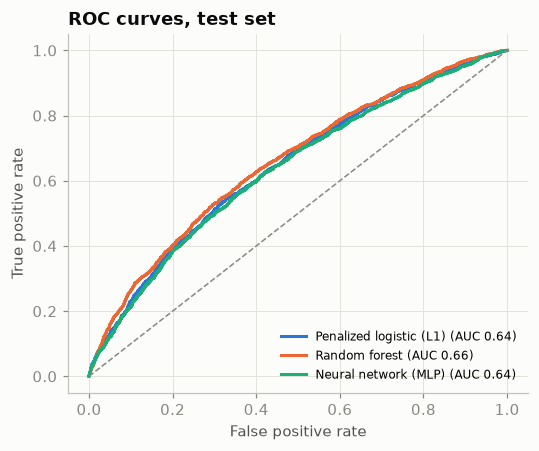

In [5]:
fig, ax = plt.subplots(figsize=(5, 4.2))
for i, (name, s) in enumerate(scores.items()):
    fpr, tpr, _ = roc_curve(y_te, s)
    ax.plot(fpr, tpr, color=SERIES[i], lw=2, label=f"{name} (AUC {roc_auc_score(y_te, s):.2f})")
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC curves, test set")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIGURES / "04_roc.png", dpi=160); plt.show()

## 3. What drives the risk

Two views that should agree: the **lasso coefficients** (as odds ratios, holding everything else fixed) and **permutation importance** for the random forest (how much test AUC drops when a column is shuffled).

In [6]:
lasso = fitted["Penalized logistic (L1)"]
names = lasso.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lasso.named_steps["model"].coef_[0], index=names)
kept = (coef != 0).sum()
print(f"Lasso kept {kept} of {len(coef)} features (C = {lasso.named_steps['model'].C_[0]:.3g})")
odds = np.exp(coef[coef != 0]).sort_values()
odds_tbl = pd.concat([odds.head(6), odds.tail(10)]).rename("odds ratio per 1 SD / vs. baseline").round(2)
odds_tbl.index = odds_tbl.index.str.replace("num__", "").str.replace("cat__", "")
odds_tbl

Lasso kept 61 of 85 features (C = 0.0464)


discharge_to_Home                               0.69
specialty_Cardiology                            0.81
diag_1_group_Respiratory                        0.85
admission_source_Transfer                       0.89
specialty_Surgery                               0.90
specialty_Orthopedics                           0.90
A1Cresult_Not tested                            1.07
number_emergency                                1.08
specialty_Psychiatry                            1.09
on_diabetes_meds                                1.10
admission_source_Physician / clinic referral    1.10
diag_1_group_Circulatory                        1.15
payer_code_Unknown                              1.17
number_inpatient                                1.23
discharge_to_Transferred to another hospital    1.29
discharge_to_Skilled nursing / care facility    1.50
Name: odds ratio per 1 SD / vs. baseline, dtype: float64

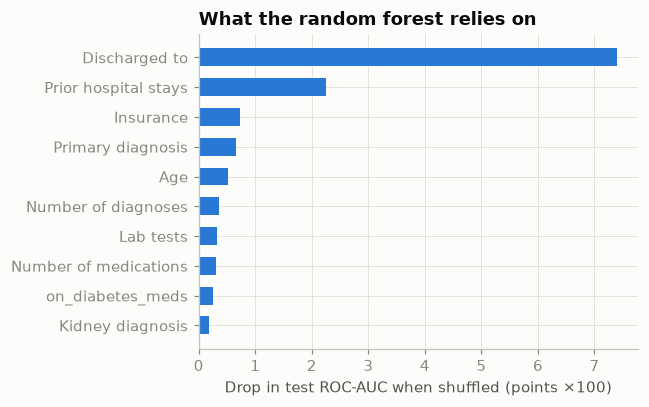

In [7]:
rf = fitted["Random forest"]
perm = permutation_importance(rf, X_te, y_te, scoring="roc_auc", n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_te.columns).sort_values(ascending=False)
top = imp.head(10)

LABEL = {"number_inpatient": "Prior hospital stays", "discharge_to": "Discharged to", "number_emergency": "Prior ER visits",
         "number_diagnoses": "Number of diagnoses", "time_in_hospital": "Days in hospital", "num_medications": "Number of medications",
         "diag_1_group": "Primary diagnosis", "age_mid": "Age", "number_outpatient": "Prior outpatient visits",
         "num_lab_procedures": "Lab tests", "admission_source": "Admitted from", "specialty": "Admitting specialty",
         "payer_code": "Insurance", "A1Cresult": "A1C result", "has_heart_dx": "Heart diagnosis", "num_procedures": "Procedures",
         "admission_type": "Admission type", "race": "Race", "has_kidney_dx": "Kidney diagnosis", "meds_changed": "Meds changed",
         "on_Insulin": "On insulin", "insulin_dose_changed": "Insulin dose changed", "max_glu_serum": "Glucose test"}
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.barh([LABEL.get(c, c) for c in top.index[::-1]], top.values[::-1] * 100, color=SERIES[0], height=0.6)
ax.set_xlabel("Drop in test ROC-AUC when shuffled (points ×100)"); ax.set_title("What the random forest relies on")
plt.tight_layout(); plt.savefig(FIGURES / "04_importance.png", dpi=160); plt.show()

## 4. Patient segments

A depth-3 decision tree with at least 1,500 patients per leaf gives a handful of segments that are easy to describe and act on. Each one is defined by 2–3 rules instead of a black-box score.

In [8]:
seg_X = pd.get_dummies(p[["number_inpatient", "number_emergency", "number_diagnoses", "time_in_hospital",
                           "age_mid", "has_heart_dx", "discharge_to"]], dtype=int)
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=1500, class_weight=None, random_state=0).fit(seg_X, y)
print(export_text(tree, feature_names=list(seg_X.columns), show_weights=False, decimals=1))

|--- discharge_to_Skilled nursing / care facility <= 0.5
|   |--- number_inpatient <= 1.5
|   |   |--- discharge_to_Home <= 0.5
|   |   |   |--- class: 0
|   |   |--- discharge_to_Home >  0.5
|   |   |   |--- class: 0
|   |--- number_inpatient >  1.5
|   |   |--- class: 0
|--- discharge_to_Skilled nursing / care facility >  0.5
|   |--- number_inpatient <= 0.5
|   |   |--- age_mid <= 80.0
|   |   |   |--- class: 0
|   |   |--- age_mid >  80.0
|   |   |   |--- class: 0
|   |--- number_inpatient >  0.5
|   |   |--- class: 0



In [9]:
leaf = tree.apply(seg_X)
p["segment_leaf"] = leaf

def leaf_rules(tree, cols):
    t = tree.tree_
    paths = {}
    def walk(node, rules):
        if t.children_left[node] == -1:
            paths[node] = rules; return
        f, thr = cols[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], rules + [(f, "<=", thr)])
        walk(t.children_right[node], rules + [(f, ">", thr)])
    walk(0, [])
    return paths

def describe(rules):
    out = []
    for f, op, thr in rules:
        if f.startswith("discharge_to_"):
            place = f.replace("discharge_to_", "")
            out.append(f"discharged to {place.lower()}" if op == ">" else f"not discharged to {place.lower()}")
        elif f == "has_heart_dx":
            out.append("heart diagnosis" if op == ">" else "no heart diagnosis")
        else:
            nice = {"number_inpatient": "prior stays", "number_emergency": "prior ER visits", "number_diagnoses": "diagnoses",
                    "time_in_hospital": "days in hospital", "age_mid": "age"}[f]
            out.append(f"{nice} ≤ {int(np.floor(thr))}" if op == "<=" else f"{nice} ≥ {int(np.floor(thr)) + 1}")
    return ", ".join(out)

rules = leaf_rules(tree, list(seg_X.columns))
seg = (p.groupby("segment_leaf").agg(patients=("readmit_30", "size"), readmit_pct=("readmit_30", "mean"),
                                     heart_pct=("has_heart_dx", "mean"), avg_age=("age_mid", "mean"))
         .assign(readmit_pct=lambda d: (100 * d.readmit_pct).round(1), heart_pct=lambda d: (100 * d.heart_pct).round(1),
                 share_pct=lambda d: (100 * d.patients / len(p)).round(1), avg_age=lambda d: d.avg_age.round(0))
         .sort_values("readmit_pct", ascending=False))
seg["rule"] = [describe(rules[i]) for i in seg.index]
seg["x_overall"] = (seg.readmit_pct / (100 * y.mean())).round(2)
seg[["rule", "patients", "share_pct", "readmit_pct", "x_overall", "heart_pct", "avg_age"]]

,rule,patients,share_pct,readmit_pct,x_overall,heart_pct,avg_age
segment_leaf,,,,,,,
10,"discharged to skilled nursing / care facility,...",1604,2.3,21.2,2.36,58.7,75.0
5,not discharged to skilled nursing / care facil...,1902,2.7,20.0,2.23,61.1,64.0
8,"discharged to skilled nursing / care facility,...",5950,8.5,16.2,1.80,52.0,68.0
9,"discharged to skilled nursing / care facility,...",4386,6.3,11.4,1.27,57.9,87.0
3,not discharged to skilled nursing / care facil...,13199,18.9,9.6,1.07,61.0,67.0
4,not discharged to skilled nursing / care facil...,42946,61.4,6.6,0.73,58.1,62.0


The highest-risk segments are defined almost entirely by **prior use of the hospital** and **where the patient goes next**: patients discharged to a care facility after an earlier stay, or with 2+ prior stays, are readmitted at 20–21%, more than twice the average. That points to a care-transition problem. A heart diagnosis is common in **every** segment (52–61%), so it doesn't separate risk, but it does describe who these patients are.

In [10]:
# Risk deciles from the random forest, for the "how much better than random" chart
dec = pd.DataFrame({"y": y_te, "s": scores["Random forest"]})
dec["decile"] = pd.qcut(dec.s.rank(method="first"), 10, labels=range(1, 11)).astype(int)
deciles = (dec.groupby("decile").y.mean() * 100).round(1)

best = results.sort_values("ROC-AUC", ascending=False).iloc[0]
update_results("models", {
    "comparison": results.to_dict("records"),
    "cv_auc_rf": [round(cv_auc.mean(), 3), round(cv_auc.std(), 3)],
    "base_rate": round(100 * y.mean(), 1),
    "lasso_kept": int(kept), "lasso_total": int(len(coef)),
    "importance": [{"feature": LABEL.get(k, k), "auc_drop": round(float(v), 4)} for k, v in top.items()],
    "deciles": [{"decile": int(k), "readmit_pct": float(v)} for k, v in deciles.items()],
    "segments": seg.reset_index()[["rule", "patients", "share_pct", "readmit_pct", "x_overall", "heart_pct", "avg_age"]].to_dict("records"),
    "best_model": best.model,
})
print("saved")

saved
